
# TITANIC SURVIVAL PREDICTION USING DECISION TREE

## Project Overview

This project uses machine learning to predict whether a passenger survived the Titanic disaster. A Decision Tree Classifier is trained using passenger information and compared against a simple baseline model.



## Project Objectives

- Load and explore the Titanic dataset.
- Clean and prepare the data.
- Split the data into training and testing sets.
- Build a simple baseline model.
- Train a Decision Tree Classifier.
- Evaluate accuracy using a confusion matrix.
- Study tree depth and overfitting.
- Identify important features.



## 1. Importing Required Libraries

We use Pandas and NumPy for data handling, Matplotlib for visualization, and Scikit-learn for building and evaluating machine learning models.


In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix



## 2. Loading the Dataset

The Titanic dataset contains passenger information. We use train.csv for model training and evaluation, while test.csv is reserved for making predictions on unseen passengers.


In [16]:

train_df = pd.read_csv("dataset/train.csv")
test_df = pd.read_csv("dataset/test.csv")

print("Training Data:", train_df.shape)
print("Testing Data:", test_df.shape)

train_df.head()


Training Data: (891, 12)
Testing Data: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



## 3. Defining the Prediction

The goal is to predict whether a passenger survived based on passenger class, sex, age, and fare. Survived is the target variable, while the remaining columns are the input features.



## 4. Data Preparation

We select the required columns, handle missing values, and convert the Sex column into numerical values so that the machine learning model can process the data.


In [17]:

features = ['Pclass', 'Sex', 'Age', 'Fare']

X = train_df[features].copy()
y = train_df['Survived'].copy()

X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})

X = X.fillna(X.median())

print("Missing Values:")
print(X.isnull().sum())


Missing Values:
Pclass    0
Sex       0
Age       0
Fare      0
dtype: int64



## 5. Splitting the Dataset

We divide the labelled training dataset into 80% training data and 20% testing data. Stratification maintains a similar survival distribution in both sets.


In [18]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])


Training Samples: 712
Testing Samples: 179



## 6. Building a Simple Baseline

A baseline model always predicts the most common survival outcome. It provides a simple performance benchmark to determine whether the Decision Tree performs better than a basic prediction strategy.


In [19]:

baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline Accuracy:", baseline_accuracy)


Baseline Accuracy: 0.6145251396648045



## 7. Training the Decision Tree

We train a Decision Tree Classifier with a maximum depth of 4. The model learns patterns from passenger information to predict survival outcomes.


In [25]:

model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)



## 8. Model Evaluation

We evaluate the Decision Tree using accuracy and a confusion matrix. These metrics help us understand how correctly the model predicts passenger survival on unseen validation data.


In [21]:

accuracy = accuracy_score(y_test, predictions)

print("Decision Tree Accuracy:", accuracy)
print("Baseline Accuracy:", baseline_accuracy)

cm = confusion_matrix(y_test, predictions)

print("\nConfusion Matrix:")
print(cm)


Decision Tree Accuracy: 0.776536312849162
Baseline Accuracy: 0.6145251396648045

Confusion Matrix:
[[105   5]
 [ 35  34]]



### Understanding the Confusion Matrix

- True Negative: Correctly predicted non-survivors.
- False Positive: Predicted survivor but passenger did not survive.
- False Negative: Predicted non-survivor but passenger survived.
- True Positive: Correctly predicted survivors.



## 9. Testing Tree Depth and Overfitting

We experiment with different maximum tree depths from 1 to 12. Comparing training and testing accuracy helps us understand how model complexity affects performance and identify overfitting.


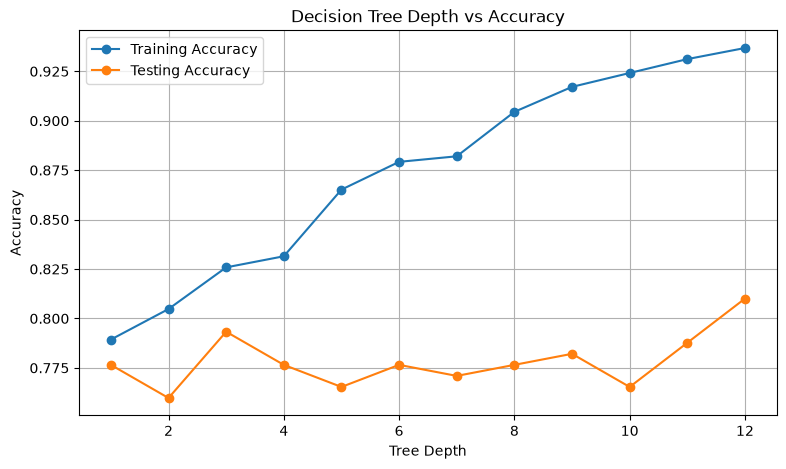

In [22]:

train_scores = []
test_scores = []
depths = range(1, 13)

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_scores.append(tree.score(X_train, y_train))
    test_scores.append(tree.score(X_test, y_test))

plt.figure(figsize=(9, 5))

plt.plot(depths, train_scores, marker='o', label='Training Accuracy')
plt.plot(depths, test_scores, marker='o', label='Testing Accuracy')

plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Depth vs Accuracy")
plt.legend()
plt.grid()
plt.show()



## 10. Feature Importance

Feature importance shows which passenger characteristics contributed most to the Decision Tree's predictions. This helps us understand which features were most useful to the model.

Sex       0.598570
Pclass    0.208209
Fare      0.098815
Age       0.094407
dtype: float64


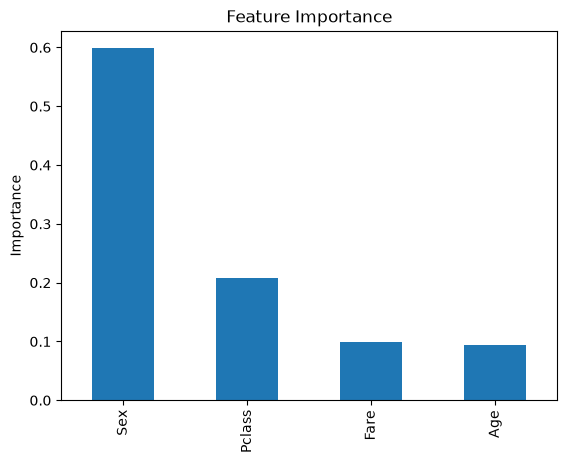

In [23]:

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

importance.plot(kind='bar', title='Feature Importance')
plt.ylabel("Importance")
plt.show()


## 11. Predictions on Separate Test Data

After evaluating the model, we train it again using the complete labelled training dataset. We then predict survival for passengers in the separate test.csv file, which does not contain survival labels.

In [24]:

X_full = train_df[features].copy()
y_full = train_df['Survived']

X_final = test_df[features].copy()

X_full['Sex'] = X_full['Sex'].map({'male': 0, 'female': 1})
X_final['Sex'] = X_final['Sex'].map({'male': 0, 'female': 1})

medians = X_full.median()

X_full = X_full.fillna(medians)
X_final = X_final.fillna(medians)

final_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

final_model.fit(X_full, y_full)

test_predictions = final_model.predict(X_final)

submission = pd.DataFrame({
    'PassengerId': test_df['PassengerId'],
    'Survived': test_predictions
})

submission.to_csv("output/predictions.csv", index=False)

print("Predictions saved successfully!")
submission.head()

OSError: Cannot save file into a non-existent directory: 'output'


# 12. Conclusion

The Decision Tree model was compared with a simple baseline to evaluate its ability to predict passenger survival. Training and testing accuracy helped us understand model performance, while feature importance identified useful passenger characteristics.

One limitation is that the model uses only four features and may not capture every factor influencing survival.


## 13. Saving the Trained Model (project 5)

We saved the trained Decision Tree model using Joblib so it can be loaded later into a Streamlit web application without training it again.



NameError: name 'model' is not defined

In [26]:
print(model)


DecisionTreeClassifier(max_depth=4, random_state=42)
